# Экспорт yolov8m-historical-line-segmenter в ONNX и подключение к Manuscript OCR

## 0. Введение

Пример для **manuscript-ocr 0.1.13**. Используем готовую модель
[yolov8m-historical-line-segmenter](https://huggingface.co/abhishekjha1008/yolov8m-historical-line-segmenter),
которая находит текстовые строки на исторических документах.

Скачаем веса, экспортируем модель в ONNX и создадим конфиг для класса `YOLO`
из Manuscript OCR. Затем посмотрим найденные строки и передадим детектор в `Pipeline`.

## 1. Установка зависимостей

Для экспорта используем Ultralytics; для загрузки весов — Hugging Face.

In [1]:
%pip install "manuscript-ocr==0.1.13" "ultralytics==8.4.176" "onnx>=1.16,<1.18" "huggingface-hub>=0.20"

  Using cached ultralytics-8.4.176-py3-none-any.whl.metadata (46 kB)
  Using cached numpy-2.4.6-cp311-cp311-macosx_14_0_arm64.whl.metadata (6.6 kB)
  Using cached ultralytics_thop-2.2.2-py3-none-any.whl.metadata (14 kB)
  Using cached numpy-2.3.5-cp311-cp311-macosx_14_0_arm64.whl.metadata (62 kB)
INFO: pip is looking at multiple versions of opencv-python to determine which version is compatible with other requirements. This could take a while.
  Using cached opencv_python-5.0.0.93-cp37-abi3-macosx_13_0_arm64.whl.metadata (19 kB)
Using cached ultralytics-8.4.176-py3-none-any.whl (1.4 MB)
Using cached numpy-2.3.5-cp311-cp311-macosx_14_0_arm64.whl (5.4 MB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.1/58.1 kB 141.5 kB/s eta 0:00:00 eta -:--:--
Using cached opencv_python-5.0.0.93-cp37-abi3-macosx_13_0_arm64.whl (48.3 MB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 876.6/876.6 kB 492.1 kB/s eta 0:00:00m eta 0:00:010:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.9/47.9 MB 4.2 MB/s e

## 2. Загрузка модели

В Ultralytics и Manuscript класс детектора называется `YOLO`.
Импортируем первый как `UltralyticsYOLO`, чтобы различать экспорт исходной модели и запуск ONNX в Manuscript.

In [2]:
from pathlib import Path
import os
import shutil
from urllib.request import urlretrieve

import onnx
import onnxruntime as ort
from PIL import Image
from IPython.display import display
from huggingface_hub import hf_hub_download
from ultralytics import YOLO as UltralyticsYOLO
from manuscript import Pipeline
from manuscript.detectors import YOLO
from manuscript.layouts import ReadingSorting
from manuscript.utils import visualize_page

MODEL_REPO = "abhishekjha1008/yolov8m-historical-line-segmenter"
MODEL_DIR = Path("models/yolov8m-historical-line-segmenter")
IMAGE_SIZE = 640
SCORE_THRESHOLD = 0.25
PROJECT_DIR = next((path for path in (Path.cwd(), *Path.cwd().parents)
                    if (path / "pyproject.toml").is_file()), Path.cwd())
IMAGES_DIR = PROJECT_DIR / "example" / "images"
MODEL_DIR.mkdir(parents=True, exist_ok=True)
ort.set_default_logger_severity(3)

checkpoint_path = hf_hub_download(
    repo_id=MODEL_REPO,
    filename="yolov8m_lineseg_v2_best.pt",
    local_dir=MODEL_DIR,
)
source_model = UltralyticsYOLO(checkpoint_path)
print("Классы исходной модели:", source_model.names)

/Users/user/manuscript-ocr/env/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


WARNING ⚠️ Ultralytics settings updated to the latest schema. Existing values were preserved where possible. 
View Ultralytics Settings with 'yolo settings' or at '/Users/user/Library/Application Support/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.


Классы исходной модели: {0: 'textline'}


## 3. Экспорт в ONNX и конфиг детектора

Экспортируем с `nms=True`: граф возвращает готовые рамки в формате
`x1, y1, x2, y2, confidence, class_id`, который принимает детектор Manuscript.
Без NMS эта YOLOv8-модель возвращает другой формат выходных тензоров.

`conf=0.05` задаёт минимальный порог внутри экспортированного графа.
Порог Manuscript `SCORE_THRESHOLD=0.25` дополнительно отбирает результаты;
его можно уменьшить до 0.05 без повторного экспорта.

Метод `YOLO.create_config()` сохраняет размер входа и соответствие классов элементам `Page`.
У этой модели класс `0` — текстовая строка, поэтому записываем `type="line"`.

В репозитории есть готовый скрипт для экспорта весов и создания конфига:
[`scripts/export_yolo.py`](../../scripts/export_yolo.py). Вместо ручных шагов этого раздела можно выполнить:

```bash
python scripts/export_yolo.py models/yolov8m-historical-line-segmenter/yolov8m_lineseg_v2_best.pt models/yolov8m-historical-line-segmenter/yolov8m_lineseg_v2_best.onnx --imgsz 640 --region-type line
```


In [3]:
exported_path = Path(source_model.export(
    format="onnx",
    imgsz=IMAGE_SIZE,  # Тот же размер затем записываем в конфиг Manuscript.
    batch=1,
    device="cpu",
    opset=17,
    dynamic=False,
    simplify=False,
    nms=True,        # Подавление дубликатов включено в ONNX-граф.
    conf=0.05,       # Нижний порог детекций, сохраняемых экспортированным графом.
    iou=0.5,
    max_det=300,
))
weights_path = MODEL_DIR / "yolov8m_lineseg_v2_best.onnx"
if exported_path.resolve() != weights_path.resolve():
    shutil.copy2(exported_path, weights_path)
onnx.checker.check_model(onnx.load(str(weights_path)))

YOLO.create_config(
    imgsz=IMAGE_SIZE,                        # Размер изображения на входе ONNX.
    region_classes={0: {"type": "line"}},  # Каждая детекция класса 0 становится строкой Page.
    output_path=MODEL_DIR / "yolov8m_lineseg_v2_best.json",
)
print("ONNX прошёл проверку; конфиг создан.")

Ultralytics 8.4.176 🚀 Python-3.11.9 torch-2.9.1 CPU (Apple M4)
Model summary (fused): 93 layers, 25,840,339 parameters, 0 gradients, 78.7 GFLOPs

PyTorch: starting from '/Users/user/manuscript-ocr/notebooks/v_0_1_13/models/yolov8m-historical-line-segmenter/yolov8m_lineseg_v2_best.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 300, 6) (49.8 MB)

ONNX: starting export with onnx 1.17.0 opset 17...
ONNX: export success ✅ 0.6s, saved as '/Users/user/manuscript-ocr/notebooks/v_0_1_13/models/yolov8m-historical-line-segmenter/yolov8m_lineseg_v2_best.onnx' (98.8 MB)

Export complete (4.8s)
Results saved to /Users/user/manuscript-ocr/notebooks/v_0_1_13/models/yolov8m-historical-line-segmenter/yolov8m_lineseg_v2_best.onnx
Predict:         yolo predict task=detect model=/Users/user/manuscript-ocr/notebooks/v_0_1_13/models/yolov8m-historical-line-segmenter/yolov8m_lineseg_v2_best.onnx imgsz=640 
Validate:        yolo val task=detect model=/Users/user/manuscript-ocr/notebooks/v_0

## 4. Загрузка локального детектора

Для пользовательской YOLO-модели нужны два файла: **ONNX-веса** и **JSON-конфиг**.
Исходный `.pt` нужен для экспорта, но не для запуска детектора Manuscript.

In [4]:
for name in ("yolov8m_lineseg_v2_best.onnx", "yolov8m_lineseg_v2_best.json"):
    description = "ONNX-веса" if name.endswith(".onnx") else "Размер входа и классы областей"
    print(f"{name}: {os.path.getsize(MODEL_DIR / name) / (1024 ** 2):.2f} МБ — {description}")

detector = YOLO(
    weights=str(MODEL_DIR / "yolov8m_lineseg_v2_best.onnx"),
    config=str(MODEL_DIR / "yolov8m_lineseg_v2_best.json"),
    score_thresh=SCORE_THRESHOLD,
    device="cpu",
)

yolov8m_lineseg_v2_best.onnx: 98.82 МБ — ONNX-веса
yolov8m_lineseg_v2_best.json: 0.00 МБ — Размер входа и классы областей


## 5. Детекция на странице

Покажем исходное изображение `img1.jpeg`, затем результат детекции.
В `Page` каждая найденная область будет иметь тип `line`, полигон и confidence.

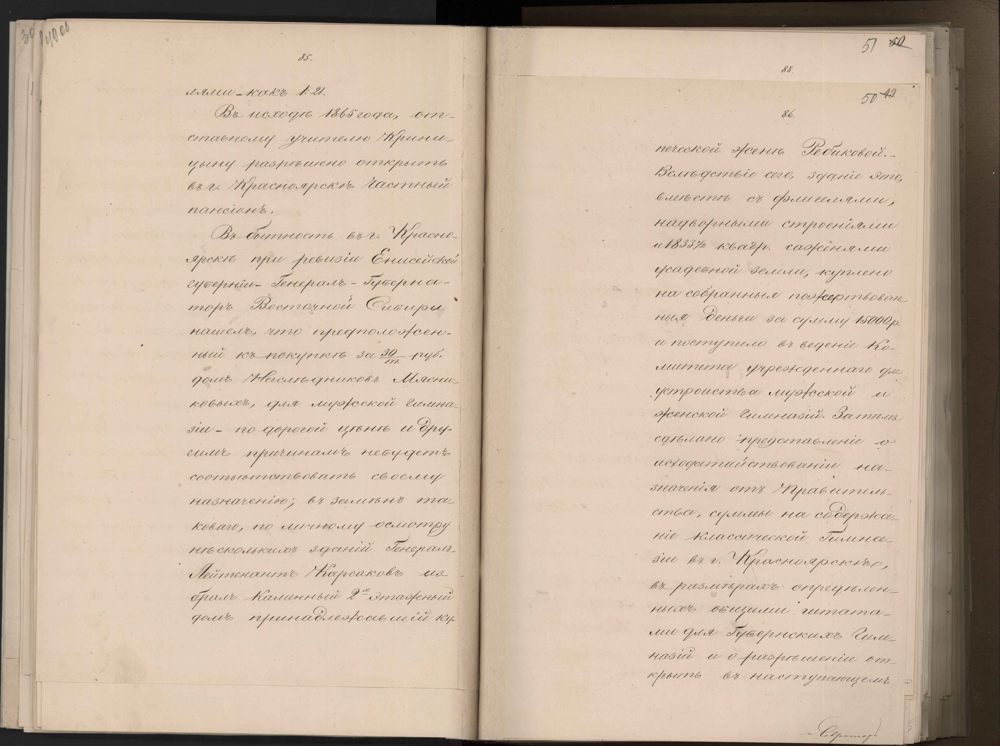

Найдено строк: 48
type=line, confidence=0.826, polygon=[(3827.62890625, 3204.865478515625), (5242.33935546875, 3204.865478515625)] …
type=line, confidence=0.818, polygon=[(3845.80322265625, 3074.19921875), (5256.4462890625, 3074.19921875)] …
type=line, confidence=0.813, polygon=[(3826.6611328125, 2788.191650390625), (5261.794921875, 2788.191650390625)] …
type=line, confidence=0.802, polygon=[(1092.9583740234375, 1572.97900390625), (2632.72021484375, 1572.97900390625)] …
type=line, confidence=0.802, polygon=[(1097.444580078125, 3283.441650390625), (2648.629150390625, 3283.441650390625)] …


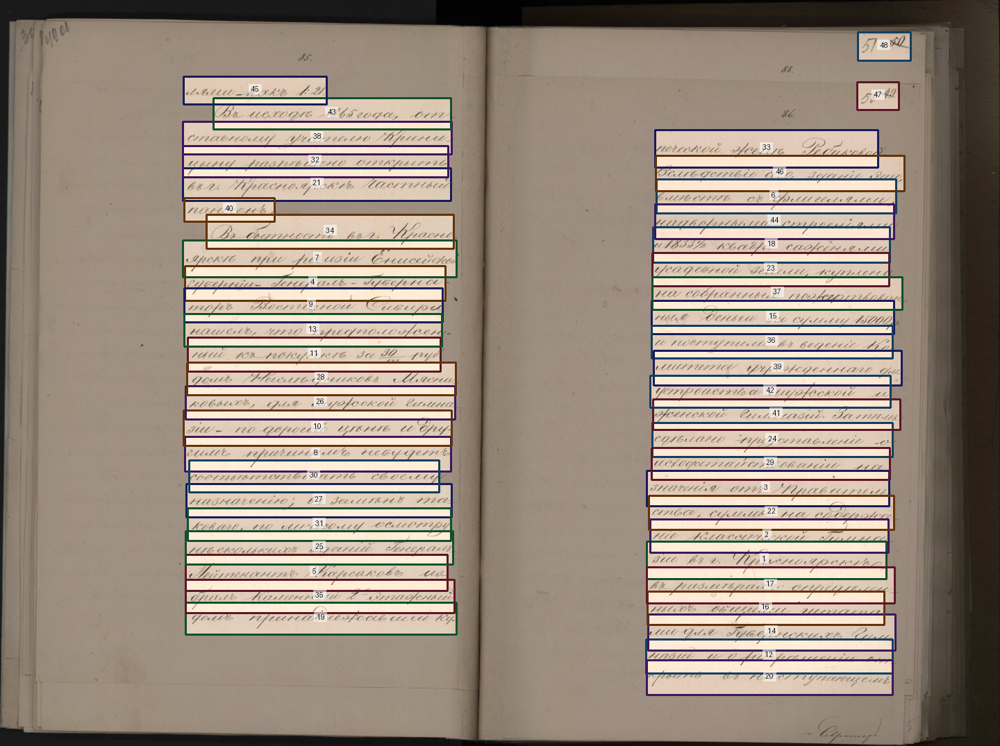

In [5]:
page_path = IMAGES_DIR / "full" / "img1.jpeg"
scene_path = IMAGES_DIR / "full" / "img5.jpeg"
IMAGE_SOURCE = "https://raw.githubusercontent.com/konstantinkozhin/manuscript-ocr/4193d8a613a7cfdec6a68cd2cdbb88b351f63964/example/images"
for path in (page_path, scene_path):
    if not path.is_file():
        path.parent.mkdir(parents=True, exist_ok=True)
        urlretrieve(f"{IMAGE_SOURCE}/{path.name}", path)

display(Image.open(page_path))
page = detector.predict(page_path)
print("Найдено строк:", len(page.children))
for region in page.children[:5]:
    print(f"type={region.type}, confidence={region.detection_confidence:.3f}, polygon={region.polygon[:2]} …")
display(visualize_page(page_path, page, max_size=1440, upscale=True))

## 6. Передача детектора в пайплайн

Передаём тот же локальный детектор в `Pipeline` и проверяем `img5.jpeg`.
`ReadingSorting` задаёт порядок найденных строк. Для этого примера распознаватель и корректор отключены;
для получения текста можно передать распознаватель с `recognition_levels=["line"]`.

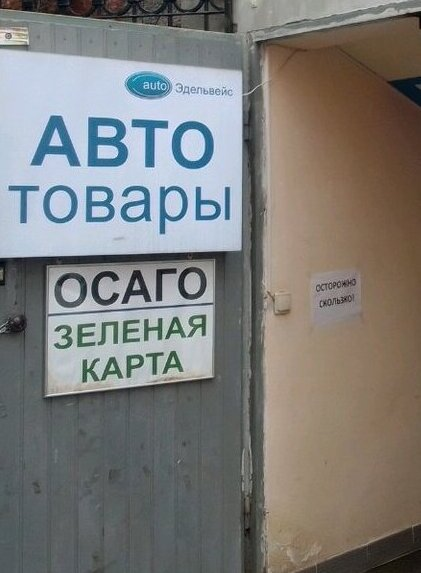

Найдено строк: 6


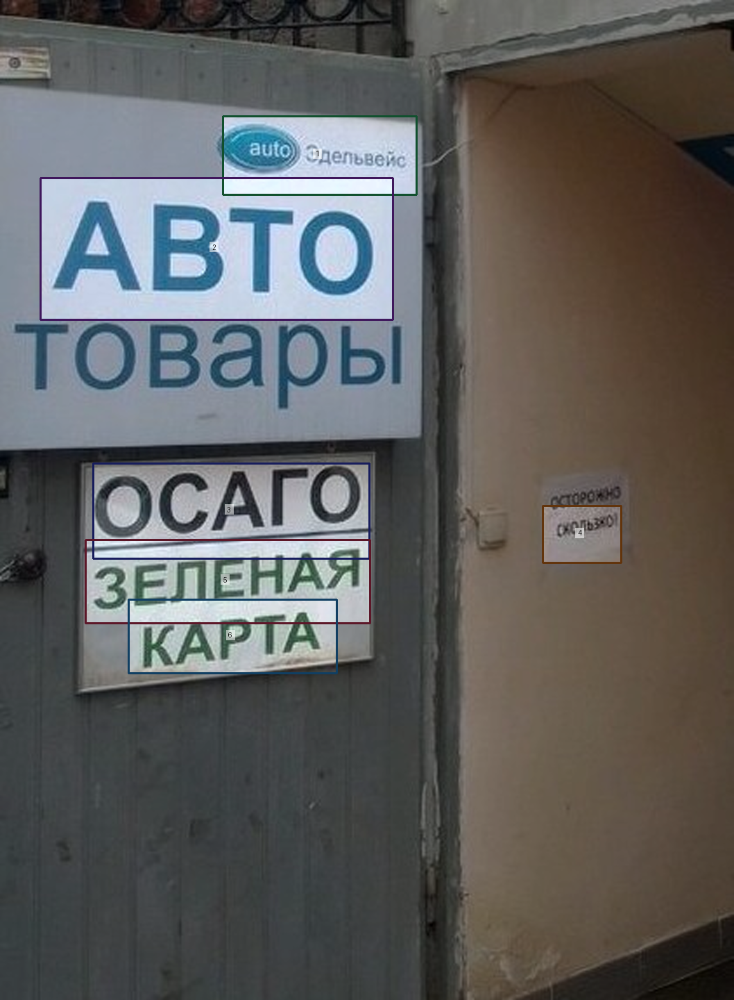

In [6]:
display(Image.open(scene_path))
pipeline = Pipeline(
    detector=detector,  # Наш yolov8m-historical-line-segmenter, загруженный из ONNX.
    layout=ReadingSorting(),
    recognizer=None,
    corrector=None,
)
page = pipeline.predict(scene_path)["page"]
print("Найдено строк:", len(page.children))
display(visualize_page(scene_path, page, max_size=1440, upscale=True))